Install Required Libraries

In [ ]:
!pip -q install transformers datasets evaluate accelerate sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.8 MB/s eta 0:00:00
ERROR: Operation cancelled by user


Import Libraries & Check GPU

In [ ]:
import numpy as np
import pandas as pd
import sklearn
import torch

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

NumPy: 2.0.2
Pandas: 2.2.2
Scikit-learn: 1.6.1
PyTorch: 2.11.0+cu128
GPU Available: True
GPU: Tesla T4


Upload and Load Dataset

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Saving Model final dataset.csv to Model final dataset.csv
Dataset Shape: (15000, 2)

Columns:
['Sentences', 'Labels']

First 5 rows:


,Sentences,Labels
0,"We were missing a dwarf in the team, and now w...",0
1,useless guy,0
2,You are so rude!,0
3,Where does the goat live?,0
4,Why are you barking like a dog?,0


Shuffle Dataset + Check Label Distribution

In [ ]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)


print("First 5 rows after shuffling:")
display(df.head())


print("\nLabel Distribution:")
print(df["Labels"].value_counts().sort_index())

First 5 rows after shuffling:


,Sentences,Labels
0,This incident took place at GTB metro station ...,3
1,Jewish men are so hot. Unlike the man bun bunn...,2
2,Go get them for lying Candice!!! Sue their Sox...,4
3,Are you mentally disabled?,0
4,"Canadian Press - REAL, Philippines (AP) - Reli...",1



Label Distribution:
Labels
0    3000
1    3000
2    3000
3    3000
4    3000
Name: count, dtype: int64


Train / Validation / Test Split

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["Labels"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["Labels"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining label distribution:")
print(train_df["Labels"].value_counts().sort_index())

print("\nValidation label distribution:")
print(val_df["Labels"].value_counts().sort_index())

print("\nTesting label distribution:")
print(test_df["Labels"].value_counts().sort_index())

Training samples: 12000
Validation samples: 1500
Testing samples: 1500

Training label distribution:
Labels
0    2400
1    2400
2    2400
3    2400
4    2400
Name: count, dtype: int64

Validation label distribution:
Labels
0    300
1    300
2    300
3    300
4    300
Name: count, dtype: int64

Testing label distribution:
Labels
0    300
1    300
2    300
3    300
4    300
Name: count, dtype: int64


Load BERT Tokenizer

In [ ]:
from transformers import BertTokenizer

model_name = "bert-base-uncased"

tokenizer = BertTokenizer.from_pretrained(model_name)

print("Tokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.vocab_size)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully!
Vocabulary size: 30522


Clean Text + Tokenize Dataset

In [ ]:
from datasets import Dataset


train_df["Sentences"] = train_df["Sentences"].astype(str)
val_df["Sentences"] = val_df["Sentences"].astype(str)
test_df["Sentences"] = test_df["Sentences"].astype(str)

train_df = train_df.rename(columns={"Labels": "labels"})
val_df = val_df.rename(columns={"Labels": "labels"})
test_df = test_df.rename(columns={"Labels": "labels"})


train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)
test_dataset = Dataset.from_pandas(test_df)


def tokenize_function(example):
    return tokenizer(
        example["Sentences"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

train_dataset = train_dataset.map(tokenize_function, batched=True)
val_dataset = val_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)

print("Tokenization completed successfully!")
print(train_dataset[0])

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Tokenization completed successfully!
{'Sentences': 'Why didnâ€™t anyone start impeachments on half of them yet', 'labels': 4, 'input_ids': [101, 2339, 2134, 2050, 30102, 30108, 2102, 3087, 2707, 17727, 5243, 22729, 2015, 2006, 2431, 1997, 2068, 2664, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_m

Prepare Dataset for Training

In [ ]:
for dataset in [train_dataset, val_dataset, test_dataset]:
    if "Sentences" in dataset.column_names:
        dataset = dataset.remove_columns(["Sentences"])

train_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

val_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

test_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

print("Training columns:", train_dataset.column_names)
print("Validation columns:", val_dataset.column_names)
print("Testing columns:", test_dataset.column_names)

Training columns: ['Sentences', 'labels', 'input_ids', 'token_type_ids', 'attention_mask']
Validation columns: ['Sentences', 'labels', 'input_ids', 'token_type_ids', 'attention_mask']
Testing columns: ['Sentences', 'labels', 'input_ids', 'token_type_ids', 'attention_mask']


Load BERT Model

In [ ]:
from transformers import BertForSequenceClassification

model_name = "bert-base-uncased"

model = BertForSequenceClassification.from_pretrained(
    model_name,
    num_labels=5
)

print("BERT model loaded successfully!")
print("Number of labels:", model.config.num_labels)

Define Training Arguments

In [ ]:
import evaluate
import numpy as np

from transformers import TrainingArguments

accuracy = evaluate.load("accuracy")
precision = evaluate.load("precision")
recall = evaluate.load("recall")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy.compute(predictions=predictions, references=labels)["accuracy"],
        "precision": precision.compute(predictions=predictions, references=labels, average="weighted")["precision"],
        "recall": recall.compute(predictions=predictions, references=labels, average="weighted")["recall"],
        "f1": f1.compute(predictions=predictions, references=labels, average="weighted")["f1"],
    }

training_args = TrainingArguments(
    output_dir="./bert_results",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=3,

    weight_decay=0.01,

    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    logging_dir="./logs",
    logging_steps=100,

    report_to="none",

    seed=42
)

print("Training arguments configured successfully!")

Create Trainer

In [ ]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

print("Trainer created successfully!")

Cell 12A: Disable Torchvision Dependency

In [ ]:
import os

os.environ["TORCHVISION_DISABLE_NMS_EXPORT"] = "1"

import sys

if "torchvision" in sys.modules:
    del sys.modules["torchvision"]

print("Torchvision dependency disabled for this session.")

Train BERT Model and Save

In [ ]:
import os
import shutil
from google.colab import files

trainer.train()

print("\nTraining completed!")


save_path = "/content/BERT_HateSpeech_Model"

model.save_pretrained(save_path)


tokenizer.save_pretrained(save_path)

print("\nModel saved successfully!")


shutil.make_archive(
    "/content/BERT_HateSpeech_Model",
    "zip",
    save_path
)

print("\nModel zipped successfully!")

files.download("/content/BERT_HateSpeech_Model.zip")

Upload the Trained Model ZIP

In [ ]:
from google.colab import files

print("Upload your trained model ZIP:")
uploaded = files.upload()

Upload your trained model ZIP:


Saving BERT_HateSpeech_Model.zip to BERT_HateSpeech_Model.zip


Extract and Load the Trained Model

In [ ]:
import zipfile
import os

from transformers import BertTokenizer, BertForSequenceClassification

zip_file = list(uploaded.keys())[0]


extract_path = "/content/BERT_HateSpeech_Model"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Model extracted successfully!")

tokenizer = BertTokenizer.from_pretrained(extract_path)

model = BertForSequenceClassification.from_pretrained(extract_path)

print("Trained BERT model loaded successfully!")
print("Number of labels:", model.config.num_labels)

Model extracted successfully!


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Trained BERT model loaded successfully!
Number of labels: 5


Evaluate the Model on the Test Set

In [ ]:
import torch
import numpy as np

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


test_dataset = test_dataset.with_format(None)



input_ids = torch.tensor(
    [x for x in test_dataset["input_ids"]],
    dtype=torch.long
)

attention_masks = torch.tensor(
    [x for x in test_dataset["attention_mask"]],
    dtype=torch.long
)

labels = torch.tensor(
    [x for x in test_dataset["labels"]],
    dtype=torch.long
)


print("\nTensor conversion successful!")
print("Input IDs:", input_ids.shape)
print("Attention Masks:", attention_masks.shape)
print("Labels:", labels.shape)


test_tensor_dataset = TensorDataset(
    input_ids,
    attention_masks,
    labels
)

test_loader = DataLoader(
    test_tensor_dataset,
    batch_size=32,
    shuffle=False
)


model.to(device)
model.eval()

predictions = []
true_labels = []


with torch.no_grad():

    for batch in test_loader:

        batch_input_ids = batch[0].to(device)
        batch_attention_masks = batch[1].to(device)
        batch_labels = batch[2].to(device)


        outputs = model(
            input_ids=batch_input_ids,
            attention_mask=batch_attention_masks
        )


        preds = torch.argmax(
            outputs.logits,
            dim=1
        )


        predictions.extend(
            preds.cpu().numpy()
        )

        true_labels.extend(
            batch_labels.cpu().numpy()
        )


accuracy = accuracy_score(
    true_labels,
    predictions
)

precision, recall, f1, _ = precision_recall_fscore_support(
    true_labels,
    predictions,
    average="weighted"
)


print("\n===== Test Results =====")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Using device: cpu

Tensor conversion successful!
Input IDs: torch.Size([1500, 128])
Attention Masks: torch.Size([1500, 128])
Labels: torch.Size([1500])

===== Test Results =====
Accuracy : 0.9720
Precision: 0.9723
Recall   : 0.9720
F1 Score : 0.9720


Classification Report

===== Classification Report =====


,precision,recall,f1-score,support
Insult,0.979310,0.946667,0.962712,300.000
Neutral,0.996633,0.986667,0.991625,300.000
Racism,0.938111,0.960000,0.948929,300.000
Sexual Abuse,0.986667,0.986667,0.986667,300.000
Threat,0.960784,0.980000,0.970297,300.000
accuracy,0.972000,0.972000,0.972000,0.972
macro avg,0.972301,0.972000,0.972046,1500.000
weighted avg,0.972301,0.972000,0.972046,1500.000


Saved: BERT_classification_report.csv


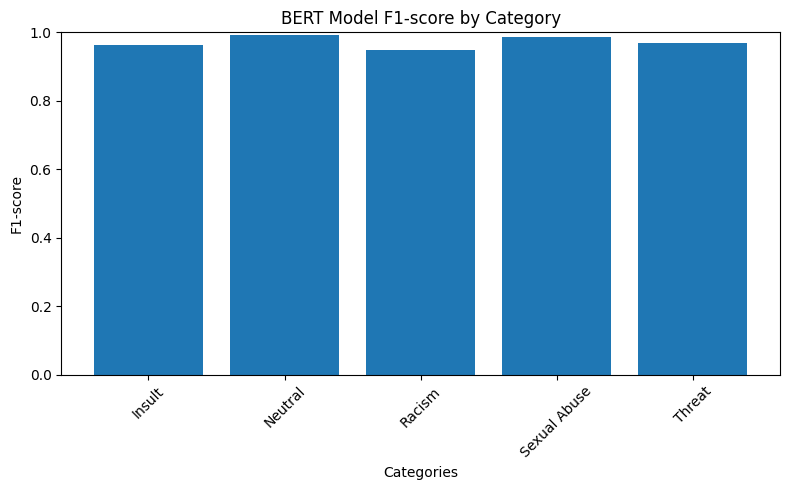

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt


label_names = [
    "Insult",
    "Neutral",
    "Racism",
    "Sexual Abuse",
    "Threat"
]


report = classification_report(
    true_labels,
    predictions,
    target_names=label_names,
    output_dict=True
)



report_df = pd.DataFrame(report).transpose()


print("===== Classification Report =====")
display(report_df)


report_df.to_csv(
    "BERT_classification_report.csv"
)

print("Saved: BERT_classification_report.csv")


f1_scores = report_df.loc[
    label_names,
    "f1-score"
]


plt.figure(figsize=(8,5))

plt.bar(
    label_names,
    f1_scores
)

plt.xlabel("Categories")
plt.ylabel("F1-score")
plt.title("BERT Model F1-score by Category")

plt.ylim(0,1)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()

EVALUATION

In [ ]:
from google.colab import files

uploaded = files.upload()

print("Upload completed!")
print("Uploaded file(s):", list(uploaded.keys()))

Saving BERT_HateSpeech_Model.zip to BERT_HateSpeech_Model.zip
Upload completed!
Uploaded file(s): ['BERT_HateSpeech_Model.zip']


In [ ]:
import zipfile
import os

zip_filename = list(uploaded.keys())[0]
extract_path = "./bert_model"

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("BERT model extracted successfully!")
print("Location:", extract_path)

for root, dirs, files_list in os.walk(extract_path):
    for file in files_list:
        print(os.path.join(root, file))

BERT model extracted successfully!
Location: ./bert_model
./bert_model/tokenizer.json
./bert_model/tokenizer_config.json
./bert_model/model.safetensors
./bert_model/config.json


In [ ]:
from google.colab import files
import pandas as pd

uploaded_dataset = files.upload()

dataset_filename = list(uploaded_dataset.keys())[0]

df = pd.read_csv(dataset_filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Saving Model final dataset.csv to Model final dataset.csv
Dataset loaded successfully!
Shape: (15000, 2)
Columns: ['Sentences', 'Labels']

First 5 rows:


,Sentences,Labels
0,"We were missing a dwarf in the team, and now w...",0
1,useless guy,0
2,You are so rude!,0
3,Where does the goat live?,0
4,Why are you barking like a dog?,0


In [ ]:
from sklearn.model_selection import train_test_split

label_mapping = {
    0: "Insult",
    1: "Neutral",
    2: "Racism",
    3: "Sexual Abuse",
    4: "Threat"
}

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["Labels"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["Labels"],
    random_state=42
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTest label distribution:")
print(test_df["Labels"].value_counts().sort_index())

Training samples: 12000
Validation samples: 1500
Testing samples: 1500

Test label distribution:
Labels
0    300
1    300
2    300
3    300
4    300
Name: count, dtype: int64


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained(extract_path)

model = AutoModelForSequenceClassification.from_pretrained(
    extract_path,
    num_labels=5
)

model.to(device)
model.eval()

print("\nBERT model loaded successfully!")
print("Number of labels:", model.config.num_labels)

Device: cpu


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


BERT model loaded successfully!
Number of labels: 5


In [ ]:
test_texts = test_df["Sentences"].astype(str).tolist()
test_labels = test_df["Labels"].tolist()

test_encodings = tokenizer(
    test_texts,
    truncation=True,
    padding="max_length",
    max_length=128,
    return_tensors="pt"
)

test_labels_tensor = torch.tensor(test_labels)

print("Test dataset tokenized successfully!")

print("Input IDs:", test_encodings["input_ids"].shape)
print("Attention Masks:", test_encodings["attention_mask"].shape)
print("Labels:", test_labels_tensor.shape)

Test dataset tokenized successfully!
Input IDs: torch.Size([1500, 128])
Attention Masks: torch.Size([1500, 128])
Labels: torch.Size([1500])


In [ ]:

from torch.utils.data import TensorDataset, DataLoader

batch_size = 16

test_dataset = TensorDataset(
    test_encodings["input_ids"],
    test_encodings["attention_mask"],
    test_labels_tensor
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

all_predictions = []
all_probabilities = []
all_true_labels = []

with torch.no_grad():

    for input_ids, attention_mask, labels in test_loader:

        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs.logits

        probabilities = torch.softmax(logits, dim=1)
        predictions = torch.argmax(logits, dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_true_labels.extend(
            labels.numpy()
        )

print("Prediction completed!")
print("Predictions:", len(all_predictions))
print("True labels:", len(all_true_labels))

Prediction completed!
Predictions: 1500
True labels: 1500


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(
    all_true_labels,
    all_predictions
)

precision = precision_score(
    all_true_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_true_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

macro_f1 = f1_score(
    all_true_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    all_true_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

print("=" * 50)
print("BERT TEST RESULTS")
print("=" * 50)

print(f"Accuracy       : {accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"Macro F1       : {macro_f1:.4f}")
print(f"Weighted F1    : {weighted_f1:.4f}")

print("\nClassification Report:")

target_names = [
    "Insult",
    "Neutral",
    "Racism",
    "Sexual Abuse",
    "Threat"
]

print(
    classification_report(
        all_true_labels,
        all_predictions,
        target_names=target_names,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

cm = confusion_matrix(
    all_true_labels,
    all_predictions
)

print(cm)

BERT TEST RESULTS
Accuracy       : 0.9953
Precision      : 0.9954
Recall         : 0.9953
Macro F1       : 0.9953
Weighted F1    : 0.9953

Classification Report:
              precision    recall  f1-score   support

      Insult     1.0000    0.9933    0.9967       300
     Neutral     0.9967    0.9967    0.9967       300
      Racism     0.9836    1.0000    0.9917       300
Sexual Abuse     0.9967    0.9967    0.9967       300
      Threat     1.0000    0.9900    0.9950       300

    accuracy                         0.9953      1500
   macro avg     0.9954    0.9953    0.9953      1500
weighted avg     0.9954    0.9953    0.9953      1500


Confusion Matrix:
[[298   0   1   1   0]
 [  0 299   1   0   0]
 [  0   0 300   0   0]
 [  0   0   1 299   0]
 [  0   1   2   0 297]]


In [ ]:
import numpy as np

bert_results = test_df.copy().reset_index(drop=True)

bert_results["BERT_Prediction"] = all_predictions

bert_results["BERT_Correct"] = (
    bert_results["Labels"] ==
    bert_results["BERT_Prediction"]
)

probabilities_array = np.array(all_probabilities)

for i, label_name in enumerate(target_names):
    bert_results[f"BERT_Prob_{label_name.replace(' ', '_')}"] = (
        probabilities_array[:, i]
    )

bert_results.to_csv(
    "bert_test_predictions.csv",
    index=False
)

print("BERT predictions saved successfully!")
print("File: bert_test_predictions.csv")

print("\nCorrect predictions:",
      bert_results["BERT_Correct"].sum())

print("Incorrect predictions:",
      (~bert_results["BERT_Correct"]).sum())

BERT predictions saved successfully!
File: bert_test_predictions.csv

Correct predictions: 1493
Incorrect predictions: 7


In [ ]:

from google.colab import files

files.download("bert_test_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>